In [3]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


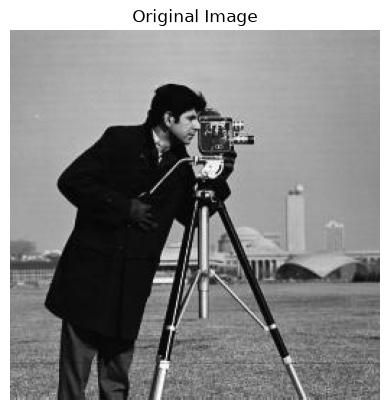

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Loading example image.
image = cv2.imread("camera_man_grayscale.jpeg", 0)

_ = plt.figure()
ax = plt.subplot()
ax.imshow(image, cmap="gray")
ax.axis("off")
ax.set_title("Original Image")
plt.show()

In [8]:
def correlate_image(image: np.ndarray, filter: np.ndarray) -> np.ndarray:
    """
    Correlate the grayscale image with the filter.
    
    Args:
        image: (N, M) The grayscale image to filter.
        filter: (K, L) The filter to apply.

    Returns:
        filtered_image: (N-K+1, M-L+1) filtered image.
    """
    image = image.copy()

    ##### YOUR CODE STARTS HERE #####
    K, L = filter.shape
    H, W = image.shape
    out_H = H-K+1
    out_W = W-L+1
    filtered_image = np.zeros((out_H, out_W))
    for x in range(out_H):
        for y in range(out_W):
            patch = image[x : x + K, y : y + L]
            filtered_image[x,y] = np.sum(filter * patch)
    ###### YOUR CODE ENDS HERE ######

    return filtered_image

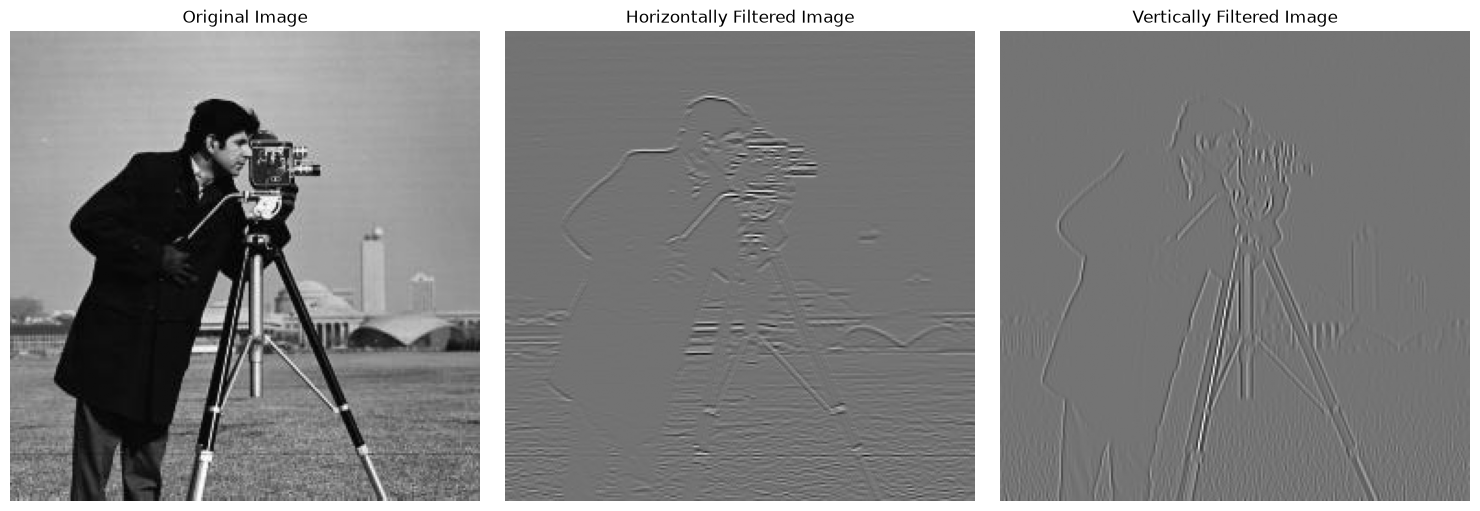

In [9]:
# NOTE: You should not need to modify the code below.

# Example a) horizontal edge detection filter.
horizontal_filter = np.array([[-1, -1, -1],
                              [2, 2, 2],
                              [-1, -1, -1]])
horizontal_filtered_image = correlate_image(image, horizontal_filter)
                              
# Example b) vertical edge detection filter.
vertical_filter = np.array([[-1, 2, -1],
                            [-1, 2, -1],
                            [-1, 2, -1]])
vertical_filtered_image = correlate_image(image, vertical_filter)

# Plot results.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(horizontal_filtered_image, cmap='gray')
axes[1].set_title('Horizontally Filtered Image')
axes[1].axis('off')

axes[2].imshow(vertical_filtered_image, cmap='gray')
axes[2].set_title('Vertically Filtered Image')
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [13]:
def create_gaussian_filter(sigma: float) -> np.ndarray:
    """
    Construct a (3, 3) normalized Gaussian filter with the given standard 
    deviation parameter.
    
    Args:
        sigma: The standard deviation of the Gaussian filter.

    Returns:
        Normalized Gaussian filter with shape (3, 3).
    """
    ##### YOUR CODE STARTS HERE #####
    # Hint: np.meshgrid() might be useful here.
    # Hint: Normalize filter so its values sum up to 1.
    # 1. Tạo tọa độ lưới 2D centered tại tâm (0,0) cho mặt nạ 3x3
    # Các chỉ số hàng/cột tương ứng: x, y in {-1, 0, 1}
    x = np.array([-1, 0, 1]) #Repeat the horizon ngang
    y = np.array([-1, 0, 1]) #Repeat the vertical dọc
    X, Y = np.meshgrid(x, y)
    a = x
    b = y
    np.meshgrid(a, b)
    # 2. Tính giá trị hàm Gaussian 2D không chuẩn hóa: exp(-(x^2 + y^2) / (2 * sigma^2))
    # Lưu ý: Hệ số hằng số 1 / (2 * pi * sigma^2) sẽ bị triệt tiêu sau khi chuẩn hóa tổng = 1.
    gaussian_filter = np.exp(-(X**2 + Y**2) / (2.0 * sigma**2))
    # 3. Chuẩn hóa để tổng các phần tử trong bộ lọc bằng 1, tổng phần tử in F = 1 -> giữ độ sáng
    gaussian_filter /= np.sum(gaussian_filter)
    
    ###### YOUR CODE ENDS HERE ######
    
    return gaussian_filter

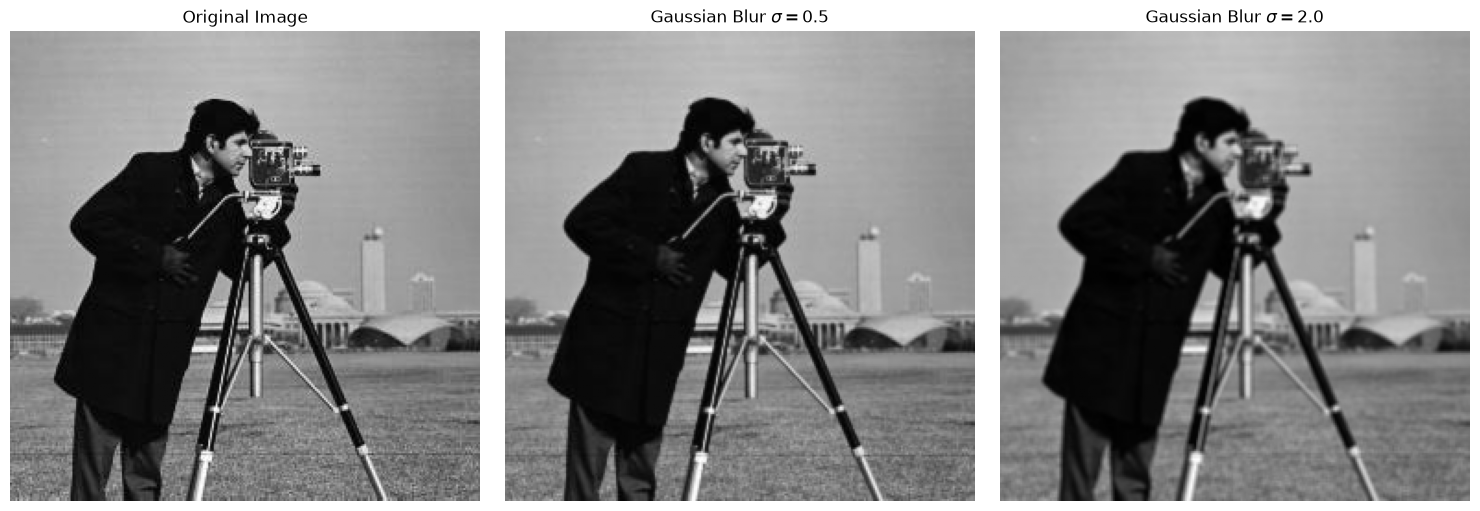

In [14]:
# NOTE: You should not need to modify the code below.

# Example a) Gaussian filter with 0.5 standard deviation.
gaussian_filter_1 = create_gaussian_filter(0.5)
gaussian_filtered_image_1 = correlate_image(image, gaussian_filter_1)
                              
# Example b) Gaussian filter with 2.0 standard deviation.
gaussian_filter_2 = create_gaussian_filter(2.0)
gaussian_filtered_image_2 = correlate_image(image, gaussian_filter_2)

# Plot results.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(gaussian_filtered_image_1, cmap='gray')
axes[1].set_title(r'Gaussian Blur $\sigma=0.5$')
axes[1].axis('off')

axes[2].imshow(gaussian_filtered_image_2, cmap='gray')
axes[2].set_title(r'Gaussian Blur $\sigma=2.0$')
axes[2].axis('off')

plt.tight_layout()
plt.show()